# README

Companion notebook to reproduce the pictures of Section 3 for the manuscript

> [1] Alexandre d’Aspremont, Frederik Kunstner, Adrien Taylor (2026). "Accelerated gradient methods
in unconstrained convex optimization." To appear in Acta Numerica.

For ease of use, the notebook can be opened in Colab through the following link: 

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AccelerationMethods/Acta-Acceleration/blob/main/Section3_figures.ipynb)

# Figures of Section 3: smooth (strongly) convex functions and models

This notebook reproduces Figures 3.1 to 3.4 of the manuscript, with `numpy` and `matplotlib` only (matplotlib 3.7 or later). Its last two sections compute the sets of possible minimizers more accurately, with an optimization solver (they also need `cvxpy`), and write the data files from which the manuscript draws these figures.

Everything is computed from the formulas of the section:

* a **history** $\mathcal H=\lbrace (w_i,g_i,f_i)\rbrace _{i=1}^k$ collects the query points $w_i$, the gradients $g_i=\nabla f(w_i)$ and the values $f_i=f(w_i)$;
* the **extremal models** of $\mathcal H$ relative to a class $\mathcal F$ (Definition 3.2) are $l_{\mathcal H}(x)=\inf\lbrace f(x):\ f\in\mathcal F\text{ interpolates }\mathcal H\rbrace$ and $u_{\mathcal H}(x)=\sup\lbrace f(x):\ f\in\mathcal F\text{ interpolates }\mathcal H\rbrace$, so that $l_{\mathcal H}\leq f\leq u_{\mathcal H}$ for every function of the class that interpolates $\mathcal H$ (Theorems 3.3 and 3.4, Corollary 3.5);
* the set $X_\star(\mathcal H)$ contains the points $x$ for which $\mathcal H$ can be completed with a triplet $(x,0,v)$, that is, the points that can still be minimizers (Section 3.6).

The three classes are $\mathcal F_{0,\infty}$ (convex), $\mathcal F_{0,L}$ ($L$-smooth convex) and $\mathcal F_{m,L}$ ($L$-smooth and $m$-strongly convex).

The data of each figure (query points, parameters of the class) are at the top of its cell: change them and run the cell again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 11, "mathtext.fontset": "cm",
    "lines.linewidth": 2.0, "legend.frameon": False,
})

# One role, one color and one line style, in every figure.
LOWER = dict(color="#4a4fb8", ls="--")          # lower model
UPPER = dict(color="#c0392b", ls="-.")          # upper model
FUNC  = dict(color="0.45", ls="--", lw=1.0)     # the function itself
INK    = "0.15"                                # points and text
ORANGE = "#e8912d"                             # possible minimizers
SHADE  = "0.92"                                # region between the two models

SAVE = False   # set to True to also write each figure as a PDF file next to the notebook

## 1. Toolbox: histories, extremal models and possible minimizers

**Models in one dimension.** For weights $\lambda$ in the simplex $\Delta_k$, let $\bar w_\lambda=\sum_{i=1}^k\lambda_iw_i$, $\bar g_\lambda=\sum_{i=1}^k\lambda_ig_i$ and $\bar f_\lambda=\sum_{i=1}^k\lambda_if_i$ be the corresponding averages of the history. The formulas below are those of the text; in one dimension, the inner products are products and the norms are absolute values.

* Convex case (Theorem 3.3):
$$l_{\mathcal H}(x)=\max_{1\leq i\leq k}\ \big\lbrace f_i+\langle g_i,x-w_i\rangle\big\rbrace ,\qquad u_{\mathcal H}(x)=\min_{\lambda\in\Delta_k}\big\lbrace \bar f_\lambda:\ \bar w_\lambda=x\big\rbrace ,$$
that is, the maximum of the tangent lines, and the convex envelope of the points $(w_i,f_i)$, with $u_{\mathcal H}(x)=+\infty$ outside of their convex hull.
* Smooth convex case (Theorem 3.4), in simplex form:
$$l_{\mathcal H}(x)=\max_{\lambda\in\Delta_k}\Big\lbrace \sum_{i=1}^k\lambda_i\Big(f_i+\langle g_i,x-w_i\rangle+\tfrac1{2L}\Vert g_i\Vert ^2\Big)-\tfrac1{2L}\Vert \bar g_\lambda\Vert ^2\Big\rbrace ,$$
$$u_{\mathcal H}(x)=\min_{\lambda\in\Delta_k}\Big\lbrace \sum_{i=1}^k\lambda_i\Big(f_i-\tfrac1{2L}\Vert g_i\Vert ^2\Big)+\tfrac1{2L}\Vert Lx-L\bar w_\lambda+\bar g_\lambda\Vert ^2\Big\rbrace .$$
* Smooth strongly convex case (Corollary 3.5): $f\in\mathcal F_{m,L}$ interpolates $\mathcal H$ if and only if $f-\tfrac m2\Vert \cdot\Vert ^2\in\mathcal F_{0,L-m}$ interpolates the shifted history
$$\tilde{\mathcal H}=\big\lbrace (w_i,\ g_i-mw_i,\ f_i-\tfrac m2\Vert w_i\Vert ^2)\big\rbrace _{i=1}^k ,$$
so that the models of $\mathcal H$ relative to $\mathcal F_{m,L}$ are those of $\tilde{\mathcal H}$ relative to $\mathcal F_{0,L-m}$, plus $\tfrac m2\Vert \cdot\Vert ^2$.

The maximum and the minimum over $\lambda$ are taken on a fine grid of the simplex, which is enough for histories of two or three points.

**Possible minimizers** (any dimension). The triplet $(x,0,v)$ can be appended to $\mathcal H$, that is, $x$ can be a minimizer with optimal value $v$, exactly when $\max_iC_i(x)\leq v\leq\min_jD_j(x)$, where
$$C_i(x)=f_i+\langle g_i,x-w_i\rangle+\tfrac m2\Vert x-w_i\Vert ^2+\tfrac{1}{2(L-m)}\Vert g_i+m(x-w_i)\Vert ^2,$$
$$D_j(x)=f_j-\tfrac m2\Vert x-w_j\Vert ^2-\tfrac{1}{2(L-m)}\Vert g_j+m(x-w_j)\Vert ^2 .$$
Hence
$$X_\star(\mathcal H)=\Big\lbrace x\in\mathbb R^d:\ \max_{1\leq i\leq k}C_i(x)\leq\min_{1\leq j\leq k}D_j(x)\Big\rbrace .$$
Setting $m=0$ gives the smooth convex case, and $L=\infty$ the convex case.

In [2]:
def history(fun, grad, points):
    "Query `fun` at `points`: returns the arrays (w, g, f) of points, gradients and values."
    w = np.asarray(points, dtype=float)
    return w, grad(w), fun(w)


def simplex_grid(k):
    "Weights lambda >= 0 summing to one, on a regular grid: one row per lambda (for k = 2 or 3)."
    if k == 2:
        t = np.linspace(0, 1, 4001)
        return np.column_stack([1 - t, t])
    n = 400
    i, j = np.meshgrid(np.arange(n + 1), np.arange(n + 1), indexing="ij")
    keep = i + j <= n
    return np.column_stack([i[keep], j[keep], n - i[keep] - j[keep]]) / n


def models_convex(x, w, g, f):
    "Extremal models relative to F_{0,inf}, in one dimension (Theorem 3.3)."
    lower = np.max(f[:, None] + g[:, None] * (x - w[:, None]), axis=0)   # max_i {f_i + g_i (x - w_i)}
    order = np.argsort(w)                                                # min {f_bar : w_bar = x}: for convex data,
    upper = np.interp(x, w[order], f[order], left=np.inf, right=np.inf)  # the linear interpolation of the points
    return lower, upper


def models_smooth(x, w, g, f, L):
    "Extremal models relative to F_{0,L}, in one dimension (Theorem 3.4, simplex forms)."
    lam = simplex_grid(len(w))                        # one row per lambda
    w_bar, g_bar = lam @ w, lam @ g                   # averages of the history, one entry per lambda
    lower, upper = np.empty_like(x), np.empty_like(x)
    for n, xn in enumerate(x):
        lower[n] = np.max(lam @ (f + g * (xn - w) + g**2 / (2 * L)) - g_bar**2 / (2 * L))
        upper[n] = np.min(lam @ (f - g**2 / (2 * L)) + (L * xn - L * w_bar + g_bar)**2 / (2 * L))
    return lower, upper


def models_strongly_convex(x, w, g, f, m, L):
    "Extremal models relative to F_{m,L} (Corollary 3.5): models of the shifted history relative to F_{0,L-m}, plus m/2 x^2."
    lower, upper = models_smooth(x, w, g - m * w, f - m / 2 * w**2, L - m)
    return lower + m / 2 * x**2, upper + m / 2 * x**2


def optimal_value_bounds(X, W, G, F, m=0.0, L=np.inf):
    '''Bounds max_i C_i(x) and min_j D_j(x) on the optimal value, if x is a minimizer (Section 3.6).

    X has shape (number of points, d); W and G have shape (k, d); F has shape (k,).
    A point x belongs to X_star(H) exactly when the first bound is below the second one.'''
    step = X[None, :, :] - W[:, None, :]                          # x - w_i, shape (k, number of points, d)
    slope = np.sum(G[:, None, :] * step, axis=2)                  # <g_i, x - w_i>
    curvature = m / 2 * np.sum(step**2, axis=2)                   # m/2 ||x - w_i||^2
    mixed = 0.0 if np.isinf(L) else np.sum((G[:, None, :] + m * step)**2, axis=2) / (2 * (L - m))
    C = F[:, None] + slope + curvature + mixed
    D = F[:, None] - curvature - mixed
    return C.max(axis=0), D.min(axis=0)

A quick check before plotting, on a random function of $\mathcal F_{m,L}$ queried at three points:

1. the models must sandwich the function;
2. the simplex forms must agree with the first expressions of the models in Theorem 3.4, in which the unknown gradient $g$ at $x$ is chosen to make the lower bound as low as possible and the upper bound as large as possible, namely
$$\min_{g\in\mathbb R^d}\ \max_{1\leq i\leq k}\ \Big\lbrace f_i+\langle g_i,x-w_i\rangle+\tfrac1{2L}\Vert g-g_i\Vert ^2\Big\rbrace \qquad\text{and}\qquad\max_{g\in\mathbb R^d}\ \min_{1\leq i\leq k}\ \Big\lbrace f_i+\langle g,x-w_i\rangle-\tfrac1{2L}\Vert g-g_i\Vert ^2\Big\rbrace ;$$
3. the minimizer and the minimal value of the function must be among the possible ones.

In [3]:
def check_toolbox(m=0.5, L=2.0, seed=0):
    rng = np.random.default_rng(seed)
    a, b = rng.uniform(0.5, 1.5, 4), rng.uniform(-2, 2, 4)
    c = (L - m) / np.sum(a**2 / 4)                    # log(1 + e^t) has curvature at most 1/4
    fun  = lambda x: m / 2 * x**2 + c * np.sum(np.logaddexp(0, np.multiply.outer(x, a) + b), axis=-1)
    grad = lambda x: m * x + c * np.sum(a / (1 + np.exp(-(np.multiply.outer(x, a) + b))), axis=-1)

    w, g, f = history(fun, grad, [-1.3, 0.2, 1.1])
    x = np.linspace(-3, 3, 61)
    lower, upper = models_strongly_convex(x, w, g, f, m, L)

    # 1. Sandwich.
    assert np.all(lower <= fun(x) + 1e-9) and np.all(fun(x) <= upper + 1e-9)

    # 2. First expressions of the models, by brute force over the unknown gradient at x (for the shifted history).
    ws, gs, fs, Ls = w, g - m * w, f - m / 2 * w**2, L - m
    gx = np.linspace(-10, 10, 8001)[None, :, None]    # candidate gradients at x
    x_, w_, g_, f_ = x[:, None, None], ws[None, None, :], gs[None, None, :], fs[None, None, :]
    lower_def = (f_ + g_ * (x_ - w_) + (gx - g_)**2 / (2 * Ls)).max(axis=2).min(axis=1) + m / 2 * x**2
    upper_def = (f_ + gx * (x_ - w_) - (gx - g_)**2 / (2 * Ls)).min(axis=2).max(axis=1) + m / 2 * x**2
    gap_lower, gap_upper = np.abs(lower - lower_def).max(), np.abs(upper - upper_def).max()
    assert max(gap_lower, gap_upper) < 1e-3           # the two forms only differ by the resolution of the grids

    # 3. The actual minimizer is a possible minimizer.
    fine = np.linspace(-3, 3, 600001)
    x_star, f_star = fine[fun(fine).argmin()], fun(fine).min()
    low, high = optimal_value_bounds(np.array([[x_star]]), w[:, None], g[:, None], f, m, L)
    assert low[0] <= f_star + 1e-9 and f_star <= high[0] + 1e-9

    print(f"all checks passed (largest gap between the two forms: lower {gap_lower:.0e}, upper {gap_upper:.0e})")


check_toolbox()

all checks passed (largest gap between the two forms: lower 5e-04, upper 2e-04)


## 2. Plotting helpers

Small functions shared by the figures.

In [4]:
def panels(ncols, width, height):
    "A row of panels, with room for a common legend below."
    return plt.subplots(1, ncols, figsize=(width, height), layout="constrained")


def legend_below(fig, handles, ncol):
    fig.legend(handles=handles, loc="outside lower center", ncol=ncol, handlelength=2.6)


def save(fig, name):
    if SAVE:
        fig.savefig(name + ".pdf")


def bare_axis(ax, w, ylim):
    "Keep only the horizontal axis, with one tick per query point."
    ax.spines[["left", "right", "top"]].set_visible(False)
    ax.set_yticks([])
    ax.set_xticks(w, [f"$w_{i + 1}$" for i in range(len(w))], fontsize=13)
    ax.set_ylim(ylim)
    ax.margins(x=0)


def draw_queries(ax, w, f, ylim):
    "Query points, with a thin vertical line down to the axis."
    ax.vlines(w, ylim[0], f, color="0.6", ls="--", lw=0.8)
    ax.plot(w, f, "o", color=INK, ms=7, mec="white", mew=1.2, zorder=5)


def draw_models(ax, x, lower, upper, ylim):
    "Lower and upper models, and the region between them (the upper model may be infinite)."
    top = np.minimum(upper, ylim[1])                       # clip infinite values to the top of the frame
    ax.fill_between(x, lower, top, where=lower <= top, color=SHADE, lw=0)
    ax.plot(x, lower, **LOWER)
    finite = np.isfinite(upper)
    ax.plot(x[finite], upper[finite], **UPPER)
    for edge in (x[finite][0], x[finite][-1]):             # vertical walls where it jumps to infinity
        if x[0] < edge < x[-1]:
            ax.vlines(edge, np.interp(edge, x[finite], upper[finite]), ylim[1], **UPPER)


H_LOWER = Line2D([], [], label=r"lower model $l_{\mathcal{H}}$", **LOWER)
H_UPPER = Line2D([], [], label=r"upper model $u_{\mathcal{H}}$", **UPPER)
H_FUNC  = Line2D([], [], label=r"$f$ (sampled)", **FUNC)

## 3. The function sampled in Figures 3.1 to 3.3

The three one-dimensional figures sample the same convex function, with two sharp bends at $\pm1.5$ and nearly affine elsewhere,
$$f(x)=1.25\,\ln\cosh\big(2(x+1.5)\big)+1.25\,\ln\cosh\big(2(x-1.5)\big)+\tfrac{x^2}{50}-c,$$
where the constant $c$ sets the minimum to $f(0)=0.3$. Its largest curvature is $\sup f''\approx5.04$, so that $f\in\mathcal F_{0,L}$ with $L=5.1$, the value used in the figures.

In [5]:
def fun(x):
    f0 = lambda x: 1.25 * np.log(np.cosh(2 * (x + 1.5))) + 1.25 * np.log(np.cosh(2 * (x - 1.5))) + x**2 / 50
    return f0(x) - f0(0.0) + 0.3                   # vertical shift: the minimum is f(0) = 0.3


def grad(x):
    return 2.5 * np.tanh(2 * (x + 1.5)) + 2.5 * np.tanh(2 * (x - 1.5)) + x / 25

## 4. Figure 3.1: extremal models of a convex function

The function is queried at three points. Left: the information $\mathcal H$, that is, three values and three slopes. Right: knowing only that $f$ is convex, its graph lies in the shaded region, between the lower model $l_{\mathcal H}(x)=\max_i\lbrace f_i+\langle g_i,x-w_i\rangle\rbrace$, the maximum of the tangent lines, and the upper model $u_{\mathcal H}$, the convex envelope of the three points, which is infinite outside of $[w_1,w_3]$.

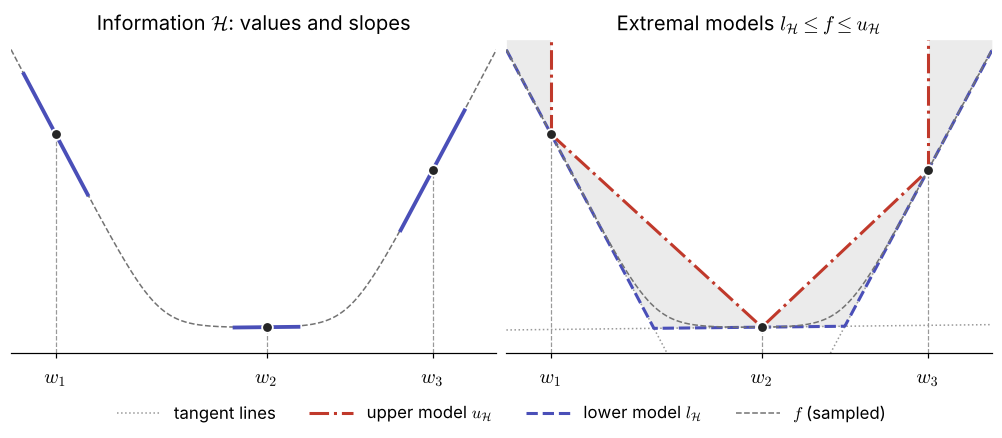

In [6]:
w, g, f = history(fun, grad, [-3.1, 0.2, 2.8])               # three query points

x, ylim = np.arange(-380, 381) / 100, (-0.8, 12.5)           # grid of step 0.01, which contains the query points
lower, upper = models_convex(x, w, g, f)

fig, (left, right) = panels(2, 9, 3.9)

left.set_title(r"Information $\mathcal{H}$: values and slopes")
left.plot(x, fun(x), **FUNC)
for wi, gi, fi in zip(w, g, f):                              # a short piece of each tangent line shows the slope
    left.plot([wi - 0.5, wi + 0.5], [fi - 0.5 * gi, fi + 0.5 * gi], color=LOWER["color"], lw=2.5)
draw_queries(left, w, f, ylim)

right.set_title(r"Extremal models $l_{\mathcal{H}} \leq f \leq u_{\mathcal{H}}$")
for wi, gi, fi in zip(w, g, f):
    right.plot(x, fi + gi * (x - wi), color="0.6", ls=":", lw=1.0)
draw_models(right, x, lower, upper, ylim)
right.plot(x, fun(x), **FUNC)
draw_queries(right, w, f, ylim)

for ax in (left, right):
    bare_axis(ax, w, ylim)
H_TANGENT = Line2D([], [], color="0.6", ls=":", lw=1.0, label="tangent lines")
legend_below(fig, [H_TANGENT, H_UPPER, H_LOWER, H_FUNC], ncol=4)
save(fig, "fig_models_convex")
plt.show()

## 5. Figure 3.2: extremal models of a smooth convex function

The function is queried at two points, and it is known to be $L$-smooth and convex. Left: each query gives a tangent line below $f$ and a tangent parabola of curvature $L$ above $f$,
$$f_i+\langle g_i,x-w_i\rangle\ \leq\ f(x)\ \leq\ f_i+\langle g_i,x-w_i\rangle+\tfrac L2\Vert x-w_i\Vert ^2 .$$
Right: the extremal models. The lower model follows the tangent lines and rounds their kink with an arc of curvature $L$; the upper model is the convex hull of the two parabolas.

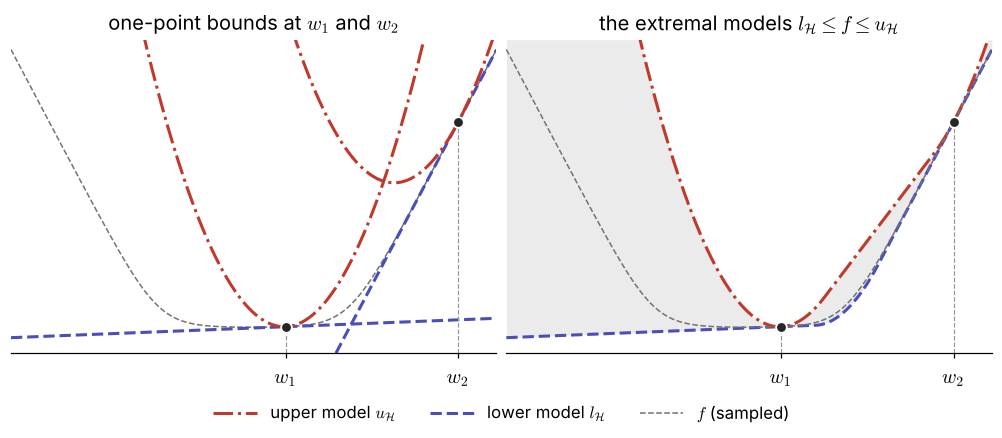

In [7]:
L = 5.1                                                      # smoothness parameter of the class
w, g, f = history(fun, grad, [0.5, 3.2])                     # two query points

x, ylim = np.arange(-380, 381) / 100, (-0.8, 12.5)
lower, upper = models_smooth(x, w, g, f, L)

fig, (left, right) = panels(2, 9, 3.9)

left.set_title("one-point bounds at $w_1$ and $w_2$")
left.plot(x, fun(x), **FUNC)
for wi, gi, fi in zip(w, g, f):
    left.plot(x, fi + gi * (x - wi), **LOWER)                            # tangent line, below f
    left.plot(x, fi + gi * (x - wi) + L / 2 * (x - wi)**2, **UPPER)      # tangent parabola, above f
draw_queries(left, w, f, ylim)

right.set_title(r"the extremal models $l_{\mathcal{H}} \leq f \leq u_{\mathcal{H}}$")
draw_models(right, x, lower, upper, ylim)
right.plot(x, fun(x), **FUNC)
draw_queries(right, w, f, ylim)

for ax in (left, right):
    bare_axis(ax, w, ylim)
legend_below(fig, [H_UPPER, H_LOWER, H_FUNC], ncol=3)
save(fig, "fig_models_smooth")
plt.show()

## 6. Figure 3.3: where can the optimizer be? (one dimension)

The function is queried at two points, and the result is read with the three classes. For the class $\mathcal F_{m,L}$, the sampled function is $f+\tfrac m2x^2$. On top of the extremal models, each panel shows

* in orange, the pairs $(x_\star,f_\star)$ that are the minimizer and the minimal value of some function of the class consistent with the queries, that is, $\max_iC_i(x_\star)\leq f_\star\leq\min_jD_j(x_\star)$ (the region between the refined models $l^\star_{\mathcal H}$ and $u^\star_{\mathcal H}$ of Section 3.6);
* as a thick segment on the axis, the set $X_\star(\mathcal H)$ of possible minimizers;
* as a red dot, the actual minimizer of the sampled function.

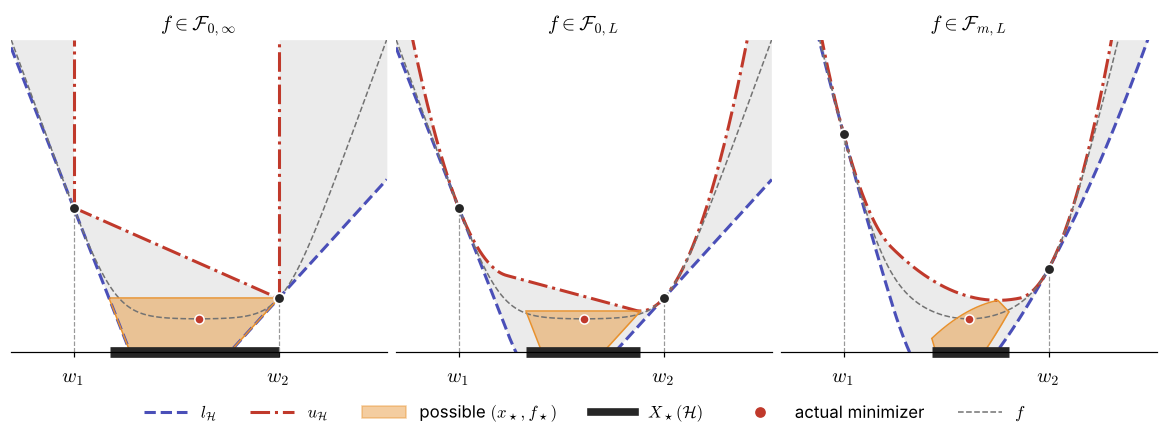

In [8]:
points = [-2.2, 1.4]                                             # two query points
classes = [(r"$f\in\mathcal{F}_{0,\infty}$", 0.0, np.inf),       # title of the panel, parameters (m, L)
           (r"$f\in\mathcal{F}_{0,L}$", 0.0, 5.1),
           (r"$f\in\mathcal{F}_{m,L}$", 1.0, 6.1)]

x, ylim = np.arange(-330, 331) / 100, (-0.8, 9.5)
fig, axes = panels(3, 10.5, 3.9)

for ax, (title, m, L) in zip(axes, classes):
    # The sampled function is f + m/2 x^2: it belongs to F_{m,L}, since f belongs to F_{0,L-m}.
    w, g, f = history(lambda x: fun(x) + m / 2 * x**2, lambda x: grad(x) + m * x, points)
    values = fun(x) + m / 2 * x**2

    if np.isinf(L):
        lower, upper = models_convex(x, w, g, f)
    else:
        lower, upper = models_strongly_convex(x, w, g, f, m, L)
    draw_models(ax, x, lower, upper, ylim)
    ax.plot(x, values, **FUNC)

    # Possible pairs (minimizer, minimal value), and their projection X_star(H) on the axis.
    low, high = optimal_value_bounds(x[:, None], w[:, None], g[:, None], f, m, L)
    possible = low <= high
    ax.fill_between(x, low, high, where=possible, color=ORANGE, alpha=0.45, lw=0)
    ax.plot(x[possible], low[possible], color=ORANGE, lw=1)
    ax.plot(x[possible], high[possible], color=ORANGE, lw=1)
    ax.plot(x[possible][[0, -1]], [ylim[0], ylim[0]], color=INK, lw=7, solid_capstyle="butt", clip_on=False)

    best = values.argmin()                             # the actual minimizer of the sampled function
    ax.plot(x[best], values[best], "o", color=UPPER["color"], ms=6, mec="white", mew=1, zorder=6)
    draw_queries(ax, w, f, ylim)
    bare_axis(ax, w, ylim)
    ax.set_title(title)

legend_below(fig, [
    Line2D([], [], label=r"$l_{\mathcal{H}}$", **LOWER), Line2D([], [], label=r"$u_{\mathcal{H}}$", **UPPER),
    Patch(facecolor=ORANGE, alpha=0.45, edgecolor=ORANGE, label=r"possible $(x_\star, f_\star)$"),
    Line2D([], [], color=INK, lw=5, label=r"$X_\star(\mathcal{H})$"),
    Line2D([], [], marker="o", ls="", color=UPPER["color"], label="actual minimizer"),
    Line2D([], [], label="$f$", **FUNC)], ncol=6)
save(fig, "fig_where_optimizer_1d")
plt.show()

## 7. Figure 3.4: where can the optimizer be? (two dimensions)

A quadratic function $f(x)=\tfrac12x^\top Qx$ is queried at three points of the plane, and the same history is read with the three classes. The shaded set is $X_\star(\mathcal H)$:

* convex: a polyhedron, $\max_i\lbrace f_i+\langle g_i,x-w_i\rangle\rbrace\leq\min_jf_j$, cut by the three tangent planes at the level of the best observed value (this panel has a larger window than the other two);
* smooth convex: a smaller polyhedron, contained in the half-spaces $\mathcal B_i=\big\lbrace x:\ \langle -g_i,x-(w_i-\tfrac1Lg_i)\rangle\geq0\big\rbrace$ (dashed);
* smooth strongly convex: an intersection of balls, contained in the balls $\mathcal B_i=\big\lbrace x:\ \Vert x-w_i+\tfrac12(\tfrac1m+\tfrac1L)g_i\Vert \leq\tfrac12(\tfrac1m-\tfrac1L)\Vert g_i\Vert \big\rbrace$ (dashed).

The arrows are the gradient steps $w_i-g_i/L$, and the red dot is the actual minimizer.

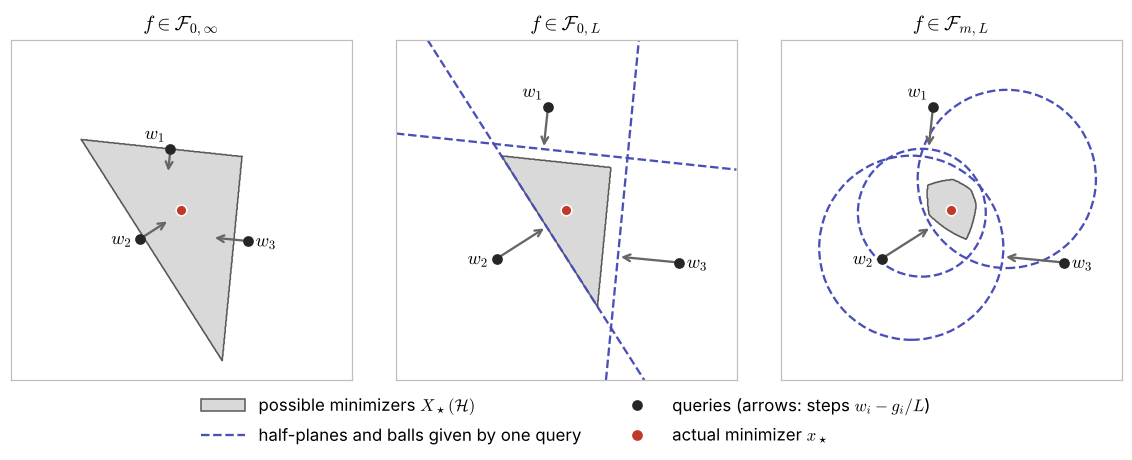

In [9]:
# A quadratic function with curvatures 2.8 and 1.4 (the first one in the direction of angle 30 degrees),
# minimized at the origin, and read with the parameters m = 1 and L = 4.
m, L = 1.0, 4.0
angle = np.deg2rad(30)
R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
Q = R @ np.diag([2.8, 1.4]) @ R.T
x_star = np.zeros(2)

radius, direction = np.array([1.6, 1.3, 1.9]), np.deg2rad([100, 215, 335])   # query points, in polar coordinates
W = radius[:, None] * np.column_stack([np.cos(direction), np.sin(direction)]) # one query point per row
G, F = W @ Q, 0.5 * np.sum((W @ Q) * W, axis=1)                               # gradients Q w_i and values

classes = [(r"$f\in\mathcal{F}_{0,\infty}$", 0.0, np.inf, 4.4),   # title, parameters (m, L), half-width of the window
           (r"$f\in\mathcal{F}_{0,L}$", 0.0, L, 2.6),
           (r"$f\in\mathcal{F}_{m,L}$", m, L, 2.6)]
fig, axes = panels(3, 10.5, 4.1)

for ax, (title, m_class, L_class, size) in zip(axes, classes):
    grid = np.linspace(-size, size, 601)
    X1, X2 = np.meshgrid(grid, grid)
    low, high = optimal_value_bounds(np.column_stack([X1.ravel(), X2.ravel()]), W, G, F, m_class, L_class)
    inside = (low <= high).reshape(X1.shape).astype(float)
    ax.contourf(X1, X2, inside, levels=[0.5, 1.5], colors=["0.85"])
    ax.contour(X1, X2, inside, levels=[0.5], colors=["0.35"], linewidths=1)

    for wi, gi in zip(W, G):
        step = wi - gi / L                                   # gradient step from w_i
        ax.annotate("", xy=step, xytext=wi, arrowprops=dict(arrowstyle="->", color="0.4", lw=1.5))
        if m_class > 0:                                      # ball B_i containing the minimizer
            center = wi - 0.5 * (1 / m_class + 1 / L_class) * gi
            ax.add_patch(plt.Circle(center, 0.5 * (1 / m_class - 1 / L_class) * np.linalg.norm(gi),
                                    fill=False, lw=1.5, **LOWER))
        elif np.isfinite(L_class):                           # half-space B_i containing the minimizer
            ax.axline(step, step + np.array([-gi[1], gi[0]]), lw=1.5, **LOWER)
    ax.plot(*W.T, "o", color=INK, ms=6, zorder=5)
    for i, (wi, shift) in enumerate(zip(W, [(-10, 6), (-12, -4), (12, -4)])):   # labels: above, left, right
        ax.annotate(f"$w_{i + 1}$", wi, xytext=shift, textcoords="offset points", ha="center", fontsize=12)
    ax.plot(*x_star, "o", color=UPPER["color"], ms=7, mec="white", mew=1, zorder=6)

    ax.set(xlim=(-size, size), ylim=(-size, size), aspect="equal", xticks=[], yticks=[], title=title)
    for spine in ax.spines.values():
        spine.set_color("0.75")

legend_below(fig, [
    Patch(facecolor="0.85", edgecolor="0.35", label=r"possible minimizers $X_\star(\mathcal{H})$"),
    Line2D([], [], lw=1.5, label="half-planes and balls given by one query", **LOWER),
    Line2D([], [], marker="o", ls="", color=INK, label=r"queries (arrows: steps $w_i - g_i/L$)"),
    Line2D([], [], marker="o", ls="", color=UPPER["color"], label=r"actual minimizer $x_\star$")], ncol=2)
save(fig, "fig_where_optimizer")
plt.show()

## 8. The sets $X_\star(\mathcal H)$ with an optimization solver

The grids used so far are accurate enough for the models: with two query points, each simplex form is a quadratic function of one weight, sampled at 4001 values, and the models are within about $10^{-7}$ of their exact values. The grids only limit the accuracy of the sets $X_\star(\mathcal H)$: in Figure 3.3, their end points are read on a grid of step $0.01$, and in Figure 3.4, their boundary is a level line computed on a grid, which cuts the corners.

These sets are convex. Indeed,
$$X_\star(\mathcal H)=\Big\lbrace x\in\mathbb R^d:\ \max_{1\leq i\leq k}C_i(x)\leq\min_{1\leq j\leq k}D_j(x)\Big\rbrace ,$$
where the functions $C_i$ are convex and the functions $D_j$ are concave. A point of the boundary is therefore obtained by maximizing a linear function $\langle u,x\rangle$ over the set, which is a small convex problem (a linear program when $m=0$), solved to the tolerance of a solver, about $10^{-8}$. The function below does so for a list of directions $u$, with [cvxpy](https://www.cvxpy.org) and the solver Clarabel that comes with it (`pip install cvxpy`). In one dimension, the directions $-1$ and $1$ give the two end points; in two dimensions, the directions of a full turn give the boundary. The next section uses it for the data of the figures of the manuscript.

In [10]:
import cvxpy as cp


def boundary_points(W, G, F, m=0.0, L=np.inf, directions=(), size=np.inf):
    """Points of the boundary of X_star(H): for each direction u, the point that maximizes <u, x> over the set.

    W and G have shape (k, d); F has shape (k,); directions has shape (number of directions, d).
    When size is finite, the set is restricted to the window max_i |x_i| <= size (X_star(H) can be unbounded if m = 0)."""
    x, u = cp.Variable(W.shape[1]), cp.Parameter(W.shape[1])
    C, D = [], []
    for wi, gi, fi in zip(W, G, F):
        mixed = 0.0 if np.isinf(L) else cp.sum_squares(gi + m * (x - wi)) / (2 * (L - m))
        C.append(fi + gi @ (x - wi) + m / 2 * cp.sum_squares(x - wi) + mixed)       # C_i(x), convex
        D.append(fi - m / 2 * cp.sum_squares(x - wi) - mixed)                       # D_i(x), concave
    constraints = [cp.max(cp.hstack(C)) <= cp.min(cp.hstack(D))]
    if np.isfinite(size):
        constraints.append(cp.norm_inf(x) <= size)
    problem = cp.Problem(cp.Maximize(u @ x), constraints)

    points = []
    for direction in directions:
        u.value = np.asarray(direction, dtype=float)                                # the problem is built once
        problem.solve(solver=cp.CLARABEL)
        assert problem.status == cp.OPTIMAL, problem.status
        points.append(x.value.copy())
    return np.array(points)


def closed_polygon(points, tolerance=1e-6):
    """Boundary points of a set of the plane, in the order of the directions, as a closed polygon.

    Consecutive points that coincide (a corner, obtained for several directions) are kept once, and the polygon
    starts and ends in the middle of its longest side, so that all its corners are drawn in the same way."""
    keep = np.linalg.norm(points - np.roll(points, 1, axis=0), axis=1) > tolerance
    keep[0] |= not keep.any()
    corners = points[keep]
    sides = np.linalg.norm(np.roll(corners, -1, axis=0) - corners, axis=1)
    corners = np.roll(corners, -(sides.argmax() + 1), axis=0)                   # the longest side joins the last corner to the first
    middle = (corners[-1] + corners[0]) / 2
    return np.vstack([middle, corners, middle])

For the data of Figure 3.3, the end points of $X_\star(\mathcal H)$ read on the grid and those given by the solver:

In [11]:
points = [-2.2, 1.4]                                             # two query points, as for Figure 3.3
x = np.arange(-380, 381) / 100                                   # grid of step 0.01

for name, m_class, L_class in [("F_{0,inf}", 0.0, np.inf), ("F_{0,L}", 0.0, 5.1), ("F_{m,L}", 1.0, 6.1)]:
    w, g, f = history(lambda x: fun(x) + m_class / 2 * x**2, lambda x: grad(x) + m_class * x, points)
    low, high = optimal_value_bounds(x[:, None], w[:, None], g[:, None], f, m_class, L_class)
    on_grid = x[low <= high]
    ends = boundary_points(w[:, None], g[:, None], f, m_class, L_class, directions=[[-1.0], [1.0]]).ravel()
    print(f"{name:10s}  grid: [{on_grid[0]:.2f}, {on_grid[-1]:.2f}]    solver: [{ends[0]:.6f}, {ends[1]:.6f}]")

F_{0,inf}   grid: [-1.57, 1.40]    solver: [-1.577239, 1.400000]
F_{0,L}     grid: [-1.01, 0.99]    solver: [-1.019654, 0.995585]
F_{m,L}     grid: [-0.65, 0.70]    solver: [-0.651258, 0.701211]


## 9. Data files of the figures of the manuscript

In the manuscript, the four figures are drawn by pgfplots from text files. This section writes these files to the folder `data/`, with the functions of the previous sections and for the same functions, query points and parameters (they are repeated at the top of each cell). The models are those of the toolbox, and the sets $X_\star(\mathcal H)$ are computed with the solver of the previous section. There are three kinds of files:

* tables (`.dat`): one column per curve, with the names of the columns on the first line, and `nan` where a curve is not drawn;
* the query points of each figure (`*_points*.dat`), with columns `x g f`;
* a few lines of TikZ code or of LaTeX macros (`.tex`), for what is drawn rather than plotted (guide lines, pieces of tangent lines, labels) and for the ticks of the axes.

The names of the files and of the columns are those read by the files `figures/fig_*.tex` of the manuscript.

In [12]:
import os

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
written = []                                           # names of the files written by this section


def write_table(name, **columns):
    "Write arrays of the same length as the columns of a table, with their names on the first line."
    table = np.column_stack(list(columns.values()))
    table = np.where(np.isfinite(table), table, np.nan)                  # infinite values are written as nan
    np.savetxt(f"{DATA_DIR}/{name}", table, fmt="%.6f", header=" ".join(columns), comments="")
    written.append(name)


def write_tex(name, lines):
    "Write lines of TikZ code or of LaTeX macros."
    with open(f"{DATA_DIR}/{name}", "w") as file:
        file.write("% generated by Section3_figures.ipynb\n" + "\n".join(lines) + "\n")
    written.append(name)


def point(x, y):
    "A point, in the coordinates of a pgfplots axis."
    return f"(axis cs:{x:.4f},{y:.4f})"


def segment(style, start, end):
    "A segment between two points."
    return rf"\draw[{style}] {point(*start)} -- {point(*end)};"


def guide(w, f, bottom):
    "Thin vertical line from the horizontal axis up to the query point (w, f)."
    return segment("gray, densely dashed, thin", (w, bottom), (w, f))


def macro(name, value):
    return rf"\newcommand{{\{name}}}{{{value}}}"


def tick_macros(prefix, suffix, w):
    "Positions and labels of the ticks of the horizontal axis: one tick per query point."
    return [macro(f"{prefix}Xticks{suffix}", ",".join(f"{wi:g}" for wi in w)),
            macro(f"{prefix}Xticklabels{suffix}", ",".join(f"$w_{i + 1}$" for i in range(len(w))))]


WALL = "red!70!black, dash dot, very thick"            # vertical line where an upper model jumps to infinity

**Figures 3.1 and 3.2.** The two figures share the table `models_1d.dat`: the function, the models of the two figures and the three tangent lines of Figure 3.1.

In [13]:
x, (bottom, top) = np.arange(-380, 381) / 100, (-0.8, 12.5)     # grid and vertical window of the two figures
L = 5.1                                                         # smoothness parameter of the class
w_c, g_c, f_c = history(fun, grad, [-3.1, 0.2, 2.8])            # Figure 3.1: three query points
w_s, g_s, f_s = history(fun, grad, [0.5, 3.2])                  # Figure 3.2: two query points

lower_c, upper_c = models_convex(x, w_c, g_c, f_c)
lower_s, upper_s = models_smooth(x, w_s, g_s, f_s, L)
tangents = {f"t{i}": fi + gi * (x - wi) for i, (wi, gi, fi) in enumerate(zip(w_c, g_c, f_c))}

# The curves. In the column u_convex_fill, the infinite values of the upper model are replaced by the top of the
# frame: it is used to shade the region between the two models.
write_table("models_1d.dat", x=x, f=fun(x),
            l_convex=lower_c, u_convex=upper_c, u_convex_fill=np.where(np.isfinite(upper_c), upper_c, top),
            l_smooth=lower_s, u_smooth=upper_s, **tangents)
write_table("models_1d_points.dat", x=w_c, g=g_c, f=f_c)
write_table("models_1d_points_smooth.dat", x=w_s, g=g_s, f=f_s)

# Figure 3.1, left panel: at each query, a guide line and a short piece of the tangent line.
pieces = []
for wi, gi, fi in zip(w_c, g_c, f_c):
    pieces += [guide(wi, fi, bottom),
               segment("blue!70!black, very thick", (wi - 0.5, fi - 0.5 * gi), (wi + 0.5, fi + 0.5 * gi))]
write_tex("models_1d_data_convex.tex", pieces)

# Figure 3.1, right panel: guide lines, and the walls of the upper model at the two extreme queries.
walls = [segment(WALL, (w_c[i], f_c[i]), (w_c[i], top)) for i in (w_c.argmin(), w_c.argmax())]
write_tex("models_1d_marks_convex.tex", [guide(wi, fi, bottom) for wi, fi in zip(w_c, f_c)] + walls)

# Figure 3.2, left panel: at each query, a guide line, the tangent line and the tangent parabola of curvature L
# (the last two as formulas, which pgfplots evaluates).
bounds = []
for wi, gi, fi in zip(w_s, g_s, f_s):
    tangent = f"{fi:.4f} + {gi:.4f}*(x - {wi:.4f})"
    bounds += [guide(wi, fi, bottom),
               rf"\addplot[blue!70!black, dashed, thick, domain=-3.8:3.8, samples=2] {{{tangent}}};",
               rf"\addplot[red!70!black, dash dot, thick, domain=-3.8:3.8, samples=121] {{{tangent} + {L / 2:.4f}*(x - {wi:.4f})^2}};"]
write_tex("models_1d_data_smooth.tex", bounds)

# Figure 3.2, right panel: guide lines.
write_tex("models_1d_marks_smooth.tex", [guide(wi, fi, bottom) for wi, fi in zip(w_s, f_s)])

# Ticks of the horizontal axes of the two figures.
write_tex("models_1d_params.tex",
          [macro("modelsL", f"{L:g}")] + tick_macros("models", "Convex", w_c) + tick_macros("models", "Smooth", w_s))

**Figure 3.3.** One table per class, with the sampled function, the two models and the bounds $\max_iC_i$ and $\min_jD_j$ on the optimal value. In the files, these two bounds are the columns `A` and `B`, and the columns `A_in` and `B_in` keep them on $X_\star(\mathcal H)$ only, to shade the possible pairs $(x_\star,f_\star)$. The two end points of $X_\star(\mathcal H)$ are computed with the solver and added to the grid, so that the shaded region and the thick segment end exactly there.

In [14]:
grid, (bottom, top) = np.arange(-380, 381) / 100, (-0.8, 12.5)
points = [-2.2, 1.4]                                            # two query points
m, L = 1.0, 5.1
classes = {"nonsmooth": (0.0, np.inf), "smooth": (0.0, L), "strong": (m, L + m)}   # name in the files: parameters (m, L)

marks = []
for name, (m_class, L_class) in classes.items():
    # The sampled function is f + m/2 x^2, as in the cell of Figure 3.3 above.
    w, g, f = history(lambda x: fun(x) + m_class / 2 * x**2, lambda x: grad(x) + m_class * x, points)

    # X_star(H) is an interval: its two end points from the solver, added to the grid.
    ends = boundary_points(w[:, None], g[:, None], f, m_class, L_class, directions=[[-1.0], [1.0]], size=grid[-1])
    left, right = np.round(ends.ravel(), 6)
    x = np.union1d(grid, [left, right])
    values = fun(x) + m_class / 2 * x**2
    if np.isinf(L_class):
        lower, upper = models_convex(x, w, g, f)
    else:
        lower, upper = models_strongly_convex(x, w, g, f, m_class, L_class)

    # Possible pairs (minimizer, minimal value), and the actual ones.
    low, high = optimal_value_bounds(x[:, None], w[:, None], g[:, None], f, m_class, L_class)
    possible = (left <= x) & (x <= right)
    best = values.argmin()
    assert possible[best] and low[best] <= values[best] <= high[best]

    write_table(f"optimizer_1d_{name}.dat", x=x, f=values,
                l=lower, u=upper, u_fill=np.where(np.isfinite(upper), upper, top),
                A=low, B=high, A_in=np.where(possible, low, np.nan), B_in=np.where(possible, high, np.nan))
    write_table(f"optimizer_1d_points_{name}.dat", x=w, g=g, f=f)

    # Drawn on top of the curves: guide lines, the set X_star(H) as a thick segment on the axis, the actual
    # minimizer and, for the class F_{0,inf}, the walls of the upper model. One macro per class.
    drawing = [guide(wi, fi, bottom) for wi, fi in zip(w, f)]
    drawing += [segment("black, line width=2.2pt", (left, bottom), (right, bottom)),
                rf"\fill[red!70!black] {point(x[best], values[best])} circle [radius=1.8pt];"]
    if np.isinf(L_class):
        drawing += [segment(WALL, (wi, fi), (wi, top)) for wi, fi in zip(w, f)]
    marks += [rf"\newcommand{{\optOneDMarks{name.capitalize()}}}{{%"] + ["  " + line for line in drawing] + ["}"]

write_tex("optimizer_1d_marks.tex", marks)
write_tex("optimizer_1d_params.tex",
          [macro("optOneDm", f"{m:g}"), macro("optOneDL", f"{L:g}"), macro("optOneDLsc", f"{L + m:g}")]
          + tick_macros("optOneD", "", w))

**Figure 3.4.** The boundary of each set $X_\star(\mathcal H)$ is written as a closed polygon, whose vertices are the boundary points given by the solver for 720 directions: the corners of the set are among them, and its curved parts (for $m>0$) are followed within $2\cdot10^{-5}$. The dashed sets $\mathcal B_i$ are written as two points per line (half-spaces) and as 361 points per circle (balls).

In [15]:
# Same quadratic function, query points and parameters as in the cell of Figure 3.4 above.
m, L = 1.0, 4.0
angle = np.deg2rad(30)
R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
Q = R @ np.diag([2.8, 1.4]) @ R.T
x_star = np.zeros(2)
radius, direction = np.array([1.6, 1.3, 1.9]), np.deg2rad([100, 215, 335])
W = radius[:, None] * np.column_stack([np.cos(direction), np.sin(direction)])
G, F = W @ Q, 0.5 * np.sum((W @ Q) * W, axis=1)

# The sets X_star(H): name in the files, parameters (m, L) of the class, half-width of the window.
turn = np.linspace(0, 2 * np.pi, 720, endpoint=False)
directions = np.column_stack([np.cos(turn), np.sin(turn)])
for name, m_class, L_class, size in [("nonsmooth", 0.0, np.inf, 4.4), ("convex", 0.0, L, 2.6), ("strong", m, L, 2.6)]:
    low, high = optimal_value_bounds(x_star[None, :], W, G, F, m_class, L_class)
    assert low[0] <= high[0]                                               # the actual minimizer is a possible one
    boundary = boundary_points(W, G, F, m_class, L_class, directions, size)
    low, high = optimal_value_bounds(boundary, W, G, F, m_class, L_class)
    assert np.abs(low - high).max() < 1e-6                                 # on the boundary: max_i C_i = min_j D_j
    polygon = closed_polygon(boundary)
    write_table(f"optimizer_region_{name}.dat", x=polygon[:, 0], y=polygon[:, 1])

# The sets B_i given by one query: boundary lines of the half-spaces (m = 0) and circles (m > 0).
turn = np.linspace(0, 2 * np.pi, 361)
lines, circles = {}, {}
for i, (wi, gi) in enumerate(zip(W, G)):
    step, along = wi - gi / L, np.array([-gi[1], gi[0]]) / np.linalg.norm(gi)   # line through w_i - g_i/L, orthogonal to g_i
    lines[f"l{i}x"], lines[f"l{i}y"] = np.array([step - 6 * along, step + 6 * along]).T
    center, size = wi - 0.5 * (1 / m + 1 / L) * gi, 0.5 * (1 / m - 1 / L) * np.linalg.norm(gi)
    circles[f"c{i}x"], circles[f"c{i}y"] = center[0] + size * np.cos(turn), center[1] + size * np.sin(turn)
write_table("optimizer_region_lines.dat", **lines)
write_table("optimizer_region_balls.dat", **circles)


def queries_and_minimizer(scale=1.0):
    """TikZ code for the query points, the gradient steps (arrows), the labels and the actual minimizer.

    The offsets of the labels are in the units of the axes: `scale` enlarges them for the panel with the larger
    window, so that the labels stay at the same distance from the points on paper."""
    nudge = np.array([[0.0, 0.16], [-0.16, 0.0], [0.16, 0.0]])             # w_1 moved up, w_2 left, w_3 right
    code = []
    for i, (wi, gi) in enumerate(zip(W, G)):
        label = wi + scale * (0.27 * gi / np.linalg.norm(gi) + nudge[i])   # on the side opposite to the arrow
        code += [rf"\draw[->, >=stealth, thick, black!60] {point(*wi)} -- {point(*(wi - gi / L))};",
                 rf"\fill[black] {point(*wi)} circle [radius=1.6pt];",
                 rf"\node[font=\footnotesize, inner sep=1pt] at {point(*label)} {{$w_{i + 1}$}};"]
    label = x_star + scale * np.array([0.08, -0.16])
    code += [rf"\fill[red!70!black] {point(*x_star)} circle [radius=2pt];",
             rf"\node[font=\footnotesize, inner sep=1pt, anchor=west, red!70!black] at {point(*label)} {{$x_\star$}};"]
    return code


write_tex("optimizer_region_points.tex", queries_and_minimizer())                        # windows [-2.6, 2.6]
write_tex("optimizer_region_points_big.tex", queries_and_minimizer(scale=4.4 / 2.6))     # window [-4.4, 4.4]

In [16]:
print(f"{len(written)} files written to {DATA_DIR}/:")
for name in sorted(written):
    print("  " + name)

23 files written to data/:
  models_1d.dat
  models_1d_data_convex.tex
  models_1d_data_smooth.tex
  models_1d_marks_convex.tex
  models_1d_marks_smooth.tex
  models_1d_params.tex
  models_1d_points.dat
  models_1d_points_smooth.dat
  optimizer_1d_marks.tex
  optimizer_1d_nonsmooth.dat
  optimizer_1d_params.tex
  optimizer_1d_points_nonsmooth.dat
  optimizer_1d_points_smooth.dat
  optimizer_1d_points_strong.dat
  optimizer_1d_smooth.dat
  optimizer_1d_strong.dat
  optimizer_region_balls.dat
  optimizer_region_convex.dat
  optimizer_region_lines.dat
  optimizer_region_nonsmooth.dat
  optimizer_region_points.tex
  optimizer_region_points_big.tex
  optimizer_region_strong.dat
